# Loan Default Risk — Full EDA Project

**Dataset:** `cs-training.csv` (Give Me Some Credit)

**Rows:** 150,000 (raw) → 150,000 (after cleaning, no rows removed) | **Columns:** 11

In this notebook we perform a complete end-to-end Exploratory Data Analysis (EDA) of a lender's credit data, from Business Understanding to the Final Business Conclusion, and then build and compare models that predict loan default.

##  Business Understanding
**Context:** this dataset belongs to a lender. Each row is a past borrower with their credit behaviour (late payments, credit utilization, debts) and personal details, plus whether they became **90+ days late within two years** (`default = 1`).

**Business goal:** management wants to understand:
- Which borrowers are most likely to default?
- How much do past late payments matter?
- Do credit utilization, age and income change the risk?
- Where should the decision cutoff sit, so defaulters are caught without rejecting too many good borrowers?

**Why this matters:** every missed default is lost money, and every wrongly rejected good borrower is lost business. These insights help with credit approval, pricing and risk-monitoring decisions.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Splitting and cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict

# Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Evaluation
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             classification_report, confusion_matrix)


In [28]:
df = pd.read_csv("cs-training.csv")
df = df.drop(columns="Unnamed: 0", errors="ignore")
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [29]:
df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "credit_utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "monthly_income",
    "NumberOfOpenCreditLinesAndLoans": "open_credit_lines",
    "NumberOfTimes90DaysLate": "late_90_plus",
    "NumberRealEstateLoansOrLines": "real_estate_loans",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfDependents": "dependents",
})

print(df.shape)
print(df.columns.tolist())

(150000, 11)
['default', 'credit_utilization', 'age', 'late_30_59', 'debt_ratio', 'monthly_income', 'open_credit_lines', 'late_90_plus', 'real_estate_loans', 'late_60_89', 'dependents']


In [30]:
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values:
monthly_income    29731
dependents         3924
dtype: int64


In [31]:
# Missing dependents most likely means none
df["dependents"] = df["dependents"].fillna(0)

# Missing income: use the median
df["monthly_income"] = df["monthly_income"].fillna(df["monthly_income"].median())

In [32]:
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values:
Series([], dtype: int64)


In [33]:
# 1. 96 and 98 are placeholder codes: blank them, then fill with the median
late = ["late_30_59", "late_60_89", "late_90_plus"]
df[late] = df[late].replace([96, 98], np.nan)
for c in late:
    df[c] = df[c].fillna(df[c].median())

# 2. Age 0 is impossible: blank it, then fill with the median age
df.loc[df["age"] == 0, "age"] = np.nan
df["age"] = df["age"].fillna(df["age"].median())

# 3. Cap extreme outliers at the 99th percentile
for c in ["credit_utilization", "debt_ratio", "monthly_income"]:
    df[c] = df[c].clip(upper=df[c].quantile(0.99))

In [34]:
print(df[["late_30_59", "late_60_89", "late_90_plus"]].isin([96, 98]).sum())
print("Rows with age 0:", (df["age"] == 0).sum())
print("Missing values:", df.isna().sum().sum())

late_30_59      0
late_60_89      0
late_90_plus    0
dtype: int64
Rows with age 0: 0
Missing values: 0


In [35]:
print(df[["credit_utilization", "debt_ratio", "monthly_income"]].describe().loc[["50%", "max"]])

     credit_utilization   debt_ratio  monthly_income
50%            0.154181     0.366508          5400.0
max            1.092956  4979.040000         23000.0


In [36]:
print("Missing values:", df.isna().sum().sum())

Missing values: 0


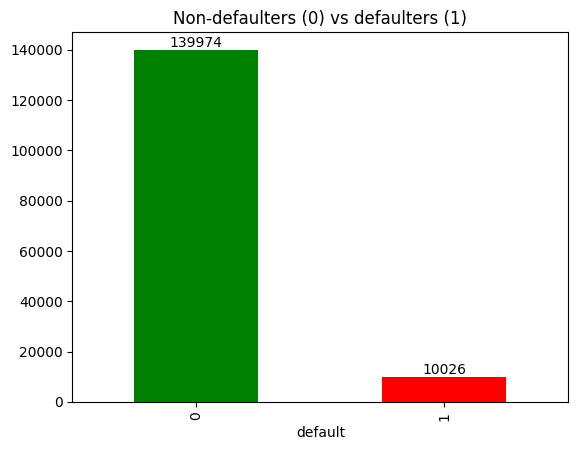

In [37]:
ax = df["default"].value_counts().sort_index().plot(kind="bar", color=["green", "red"])
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Non-defaulters (0) vs defaulters (1)")
plt.show()

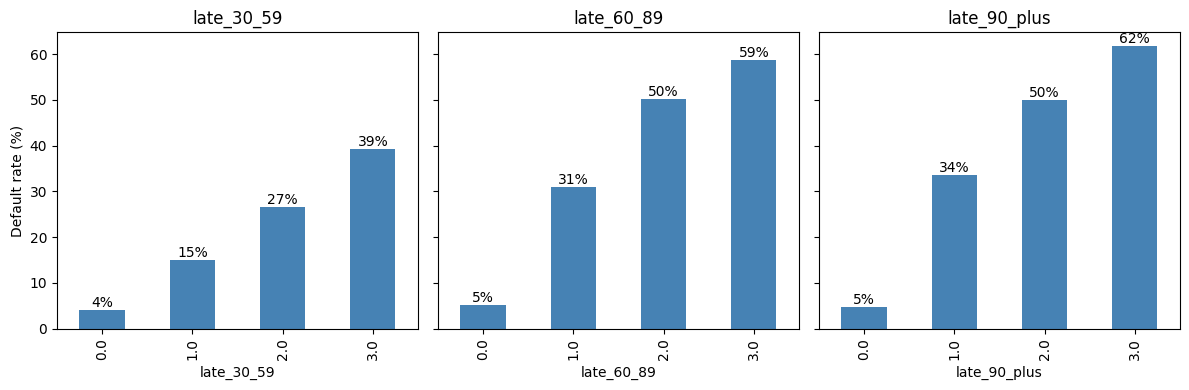

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for ax, col in zip(axes, ["late_30_59", "late_60_89", "late_90_plus"]):
    rate = df.groupby(df[col].clip(upper=3))["default"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.0f%%")
    ax.set_title(col)

axes[0].set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2006/2163226587.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax = (df.groupby(age_group)["default"].mean() * 100).plot(kind="bar", color="steelblue")


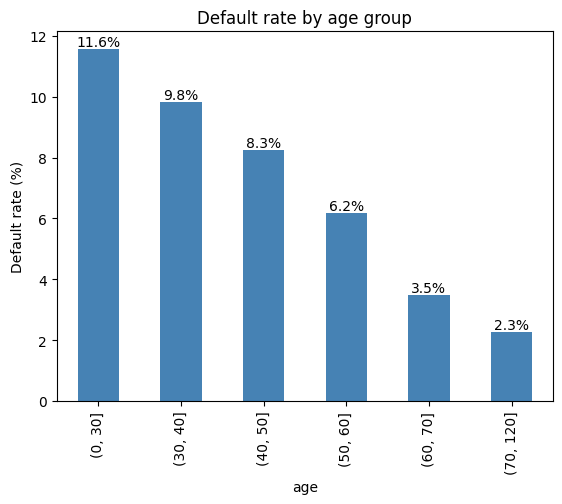

In [39]:
age_group = pd.cut(df["age"], [0, 30, 40, 50, 60, 70, 120])
ax = (df.groupby(age_group)["default"].mean() * 100).plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Default rate by age group")
plt.ylabel("Default rate (%)")
plt.show()

/tmp/ipykernel_2006/4179155859.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax = (df.groupby(util_group)["default"].mean() * 100).plot(kind="bar", color="steelblue")


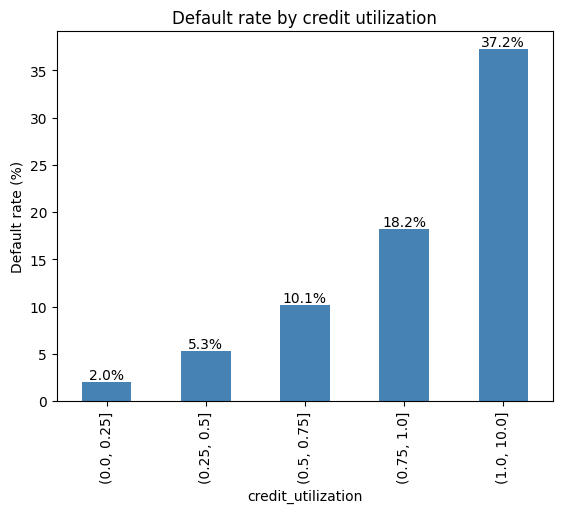

In [40]:
util_group = pd.cut(df["credit_utilization"], [0, 0.25, 0.5, 0.75, 1, 10])
ax = (df.groupby(util_group)["default"].mean() * 100).plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Default rate by credit utilization")
plt.ylabel("Default rate (%)")
plt.show()

## Business Questions
The numbers behind each answer:

In [41]:
late = ["late_30_59", "late_60_89", "late_90_plus"]
ever_late = (df[late] > 0).any(axis=1)

print("Default rate if ever late :", round(df["default"][ever_late].mean() * 100, 1), "%")
print("Default rate if never late:", round(df["default"][~ever_late].mean() * 100, 1), "%")
print("Share of borrowers ever late:", round(ever_late.mean() * 100, 1), "%")
print("Share of all defaulters who were ever late:", round(df["default"][ever_late].sum() / df["default"].sum() * 100), "%")
print("Median income, defaulters vs others:", df["monthly_income"][df["default"] == 1].median(), "vs", df["monthly_income"][df["default"] == 0].median())

Default rate if ever late : 22.0 %
Default rate if never late: 2.8 %
Share of borrowers ever late: 20.1 %
Share of all defaulters who were ever late: 66 %
Median income, defaulters vs others: 5240.0 vs 5400.0


1. **Which borrowers default most?** Those with past late payments. Borrowers ever late default at 22.0%, against 2.8% for those never late.
2. **How concentrated is the risk?** Only 20.1% of borrowers were ever late, yet they make up 66% of all defaulters.
3. **Does credit utilization matter?** Yes. The default rate rises from 2.1% (0-25% of the limit used) to 37.2% (limit exceeded).
4. **Does age matter?** Yes. Default falls from 11.6% for under-30s to 2.3% for those over 70.
5. **Does income matter?** Barely. Median income is 5,240 for defaulters and 5,400 for the rest.
6. **Where should the cutoff sit?** See sections 11 and 12: a cutoff of 0.20 finds about half of the defaulters, and lower cutoffs find more at the cost of more false alarms.

In [42]:
X = df.drop(columns="default")
y = df["default"]

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [44]:
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Default rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (120000, 10) | Test: (30000, 10)
Default rate train: 0.0668 | test: 0.0668


In [45]:
# Scale the numbers (only Logistic Regression needs this)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [46]:
# Model 1: Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [47]:
# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=50,
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=50, n_jobs=-1,
                       random_state=42)

In [48]:
# Model 3: Gradient Boosting
gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200,
                                    min_samples_leaf=100, l2_regularization=5,
                                    random_state=42)
gb.fit(X_train, y_train)


HistGradientBoostingClassifier(l2_regularization=5, learning_rate=0.05,
                               max_depth=4, max_iter=200, min_samples_leaf=100,
                               random_state=42)

In [49]:
# Compare on the test set
for name, model, X_t in [("Logistic Regression", lr, X_test_scaled),
                         ("Random Forest", rf, X_test),
                         ("Gradient Boosting", gb, X_test)]:
    prob = model.predict_proba(X_t)[:, 1]
    print(f"{name:20s} ROC-AUC {roc_auc_score(y_test, prob):.3f} | "
          f"PR-AUC {average_precision_score(y_test, prob):.3f}")

Logistic Regression  ROC-AUC 0.855 | PR-AUC 0.381
Random Forest        ROC-AUC 0.866 | PR-AUC 0.397
Gradient Boosting    ROC-AUC 0.868 | PR-AUC 0.402


In [50]:
prob = gb.predict_proba(X_test)[:, 1]

print("cutoff | flagged | precision | recall")
for t in [0.5, 0.3, 0.2, 0.16, 0.1, 0.05]:
    pred = (prob >= t).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    flagged = pred.sum()
    print(f"{t:.2f}   | {flagged:6d}  | {tp / flagged:.3f}     | {tp / y_test.sum():.3f}")

# Full report at one chosen cutoff
cutoff = 0.20
pred = (prob >= cutoff).astype(int)
print(f"\n=== Gradient Boosting at cutoff {cutoff} ===")
print(classification_report(y_test, pred, digits=3))
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_test, pred))

cutoff | flagged | precision | recall
0.50   |    577  | 0.612     | 0.176
0.30   |   1591  | 0.469     | 0.372
0.20   |   2631  | 0.388     | 0.509
0.16   |   3242  | 0.351     | 0.568
0.10   |   5047  | 0.274     | 0.690
0.05   |   9380  | 0.181     | 0.845

=== Gradient Boosting at cutoff 0.2 ===
              precision    recall  f1-score   support

           0      0.964     0.942     0.953     27995
           1      0.388     0.509     0.440      2005

    accuracy                          0.913     30000
   macro avg      0.676     0.726     0.697     30000
weighted avg      0.925     0.913     0.919     30000

Confusion matrix [[TN FP] [FN TP]]:
[[26384  1611]
 [  985  1020]]


In [51]:
# Save the trained model to a file
joblib.dump(gb, 'gradient_boosting_model.joblib')

print("Model successfully saved!")

Model successfully saved!


##  Final Business Conclusion
**What drives default:** past late payments, high credit utilization and young age. Borrowers ever late default at 22.0% against 2.8% for the rest, and borrowers over their credit limit default at 37.2%. Income, debt ratio and dependents add little on their own.

**The model:** Gradient Boosting reached a **ROC-AUC of 0.868** on 30,000 unseen borrowers (Logistic Regression 0.855, Random Forest 0.866). At a cutoff of 0.20 it finds 1,020 of the 2,005 defaulters in the test set, and about 4 in 10 flagged borrowers really default.

**Recommendations**
- Use payment history as the core of the risk score, with credit utilization and age as supporting factors. Do not approve or reject on income alone.
- Set the cutoff from the cost of a missed defaulter versus a wrongly rejected good borrower (0.20 was used here).
- Send borderline scores to manual review instead of rejecting automatically.
- Collect richer data (credit score, full repayment history, loan amount, dates) to improve on the current ceiling of about 0.87 ROC-AUC.

**Limitations**
- About half of the defaulters are missed at this cutoff, and about 1,600 good borrowers are wrongly flagged.
- The data comes from an older competition and has no dates, so performance on future borrowers was not tested.
- There is no credit score or full repayment history, which limits how much better any model can do.
- Median values and outlier caps were calculated on the full data before the split; the effect is negligible here.

This is a learning project and should not be used for real lending decisions.